In [1]:
import sys
import os
import pickle
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'fly-2023-schaffer'

In [4]:
file_id = 0
neuron_labels = ['00_759', '00_663', '00_475', '00_1250', '00_142']

In [5]:
manual_reg_lambdas = {
	'ns': {
		'bom': {
			'wb_reg_lambda': 1E-4,
		},
		'hgm': {
			'wb_reg_lambda': 1E-6,
			'wm_reg_lambda': 1E-9,
		}
	},
	'ss': {
		'bom': {
			'vb_reg_lambda': 1E-4,
		},
		'hgm': {
			'vb_reg_lambda': 1E-6,
			'wm_reg_lambda': 1E-6,
		}
	}
}

# with open('../../src/hyperparams.pkl', 'rb') as file:
#     swept_params = pickle.load(file)
# swept_reg_lambdas = dict()
# for model in swept_params[ll].keys():
# 	type_, variant = model.split('_')
# 	if variant not in swept_reg_lambdas.keys():
# 		swept_reg_lambdas[variant] = dict()
# 	if type_ not in swept_reg_lambdas[variant].keys():
# 		swept_reg_lambdas[variant][type_] = dict()
# 	for param in swept_params[ll][model]['means'].keys():
# 		swept_reg_lambdas[variant][type_][param] = swept_params[ll][model]['means'][param]['geometric']
#
#
# reg_lambdas = swept_reg_lambdas.copy()
reg_lambdas = manual_reg_lambdas.copy()

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)

# clear nan values
mask = markers.notna().all(axis=1)

traces = traces[mask]
markers = markers[mask]
states = states[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x,
								 axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
# markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

In [7]:
_, bom_man, bom_rec, bom_res, bom_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)
_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)

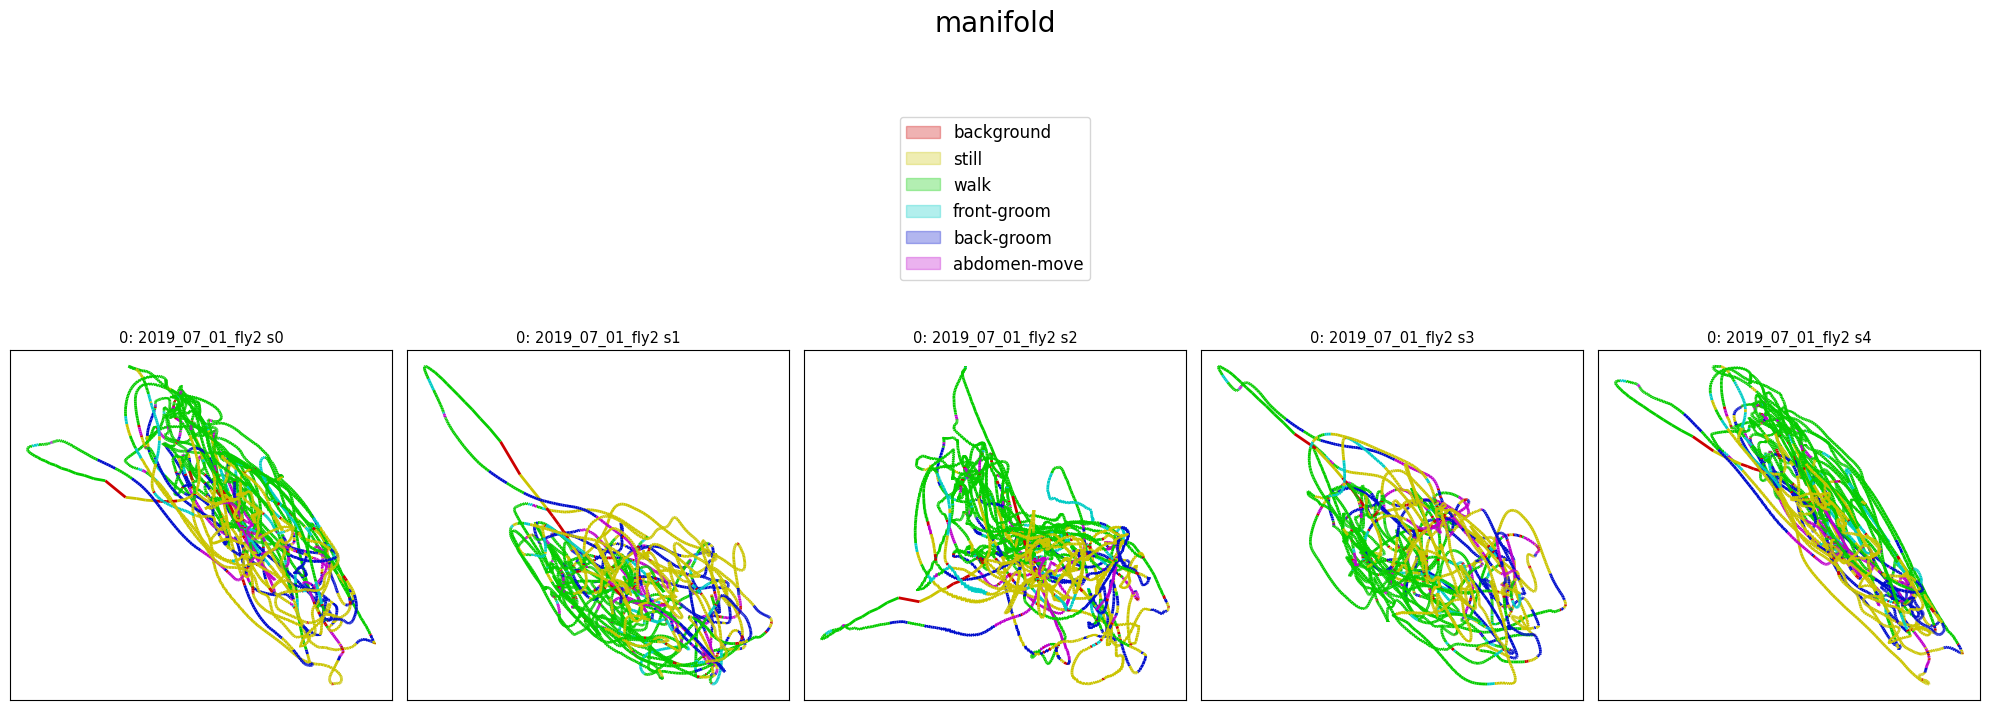

In [8]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [states for s in range(splits)],
						  None, None,
						  title='manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

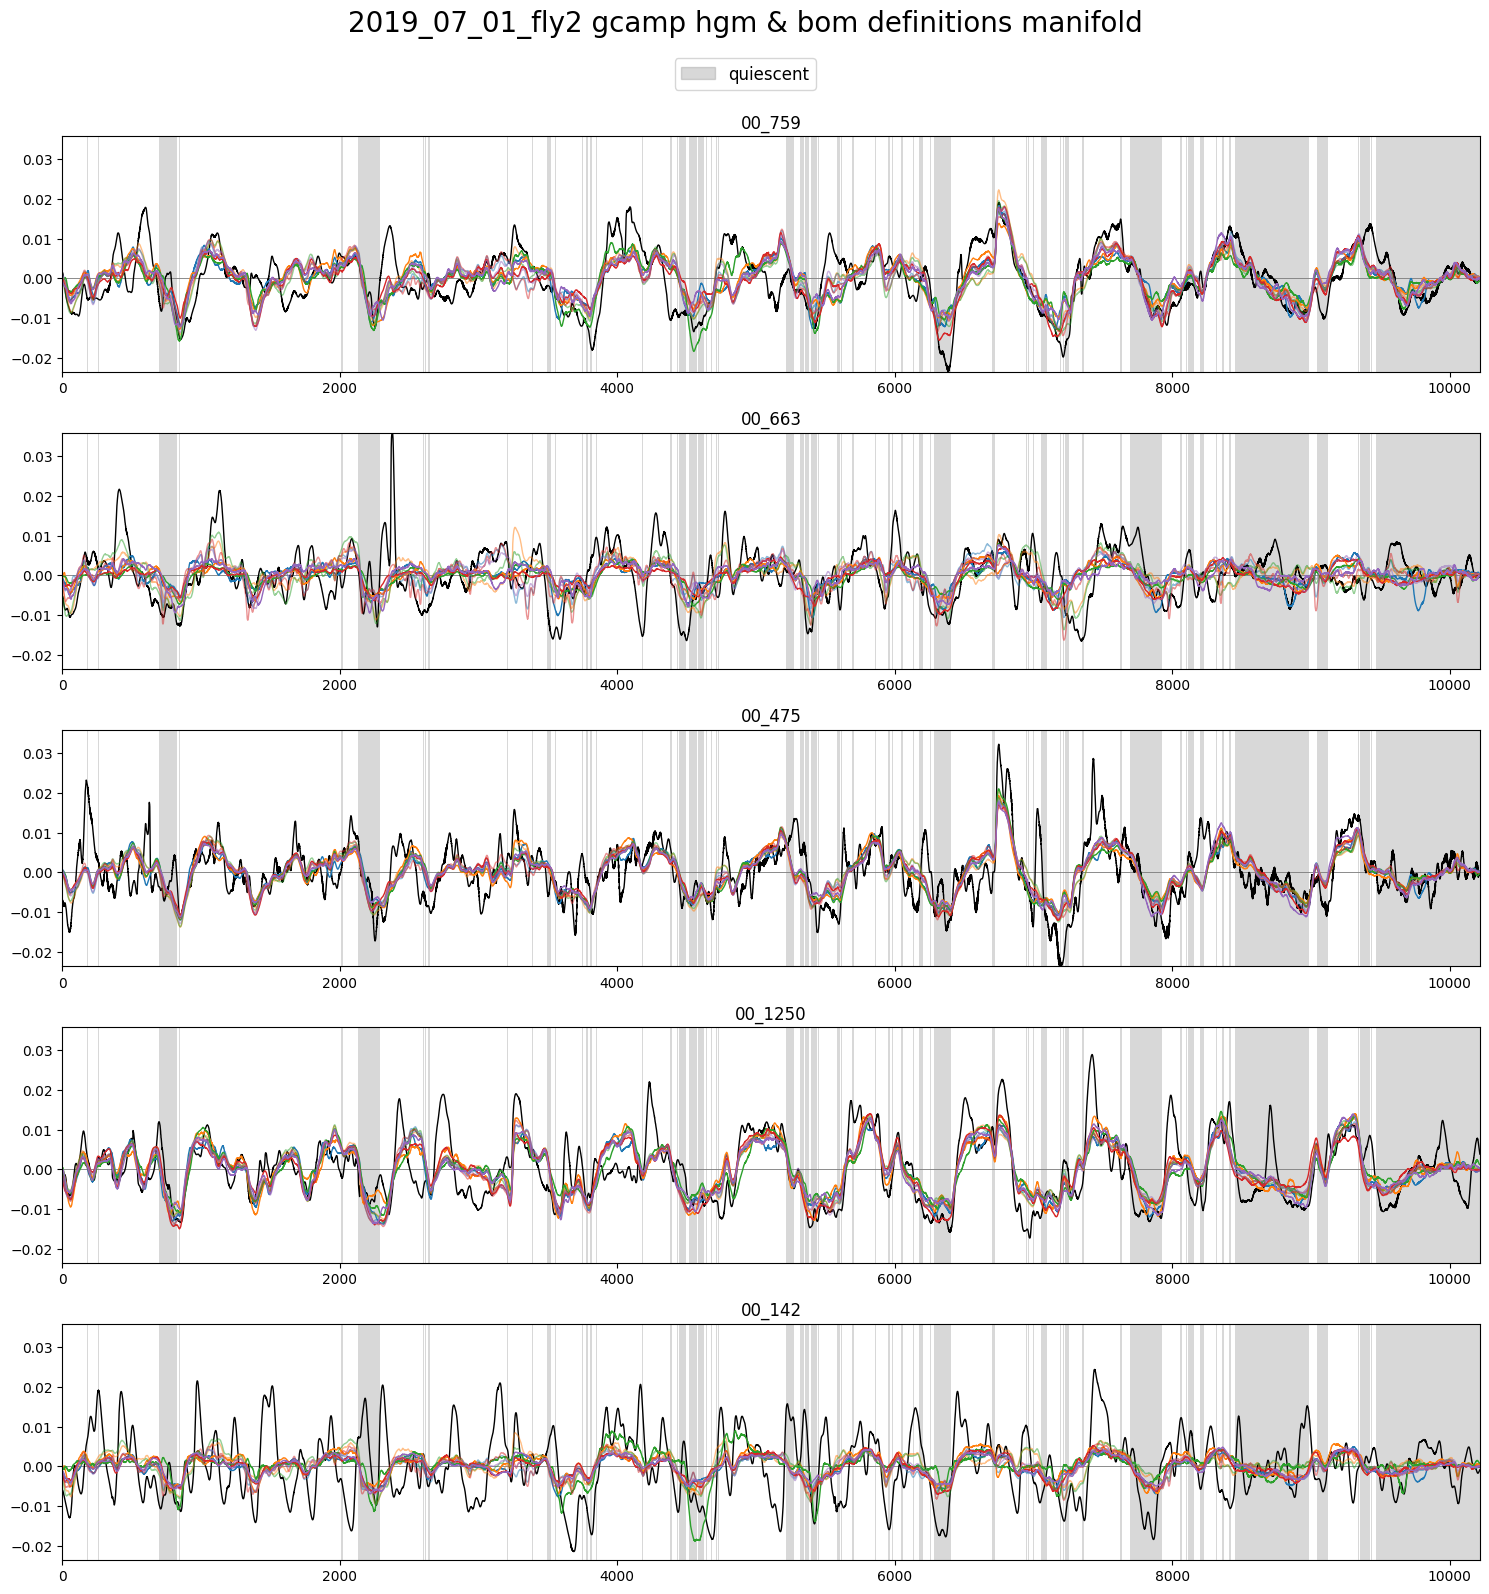

In [9]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neuron_labels] for i in range(splits)],
	[bom_rec[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

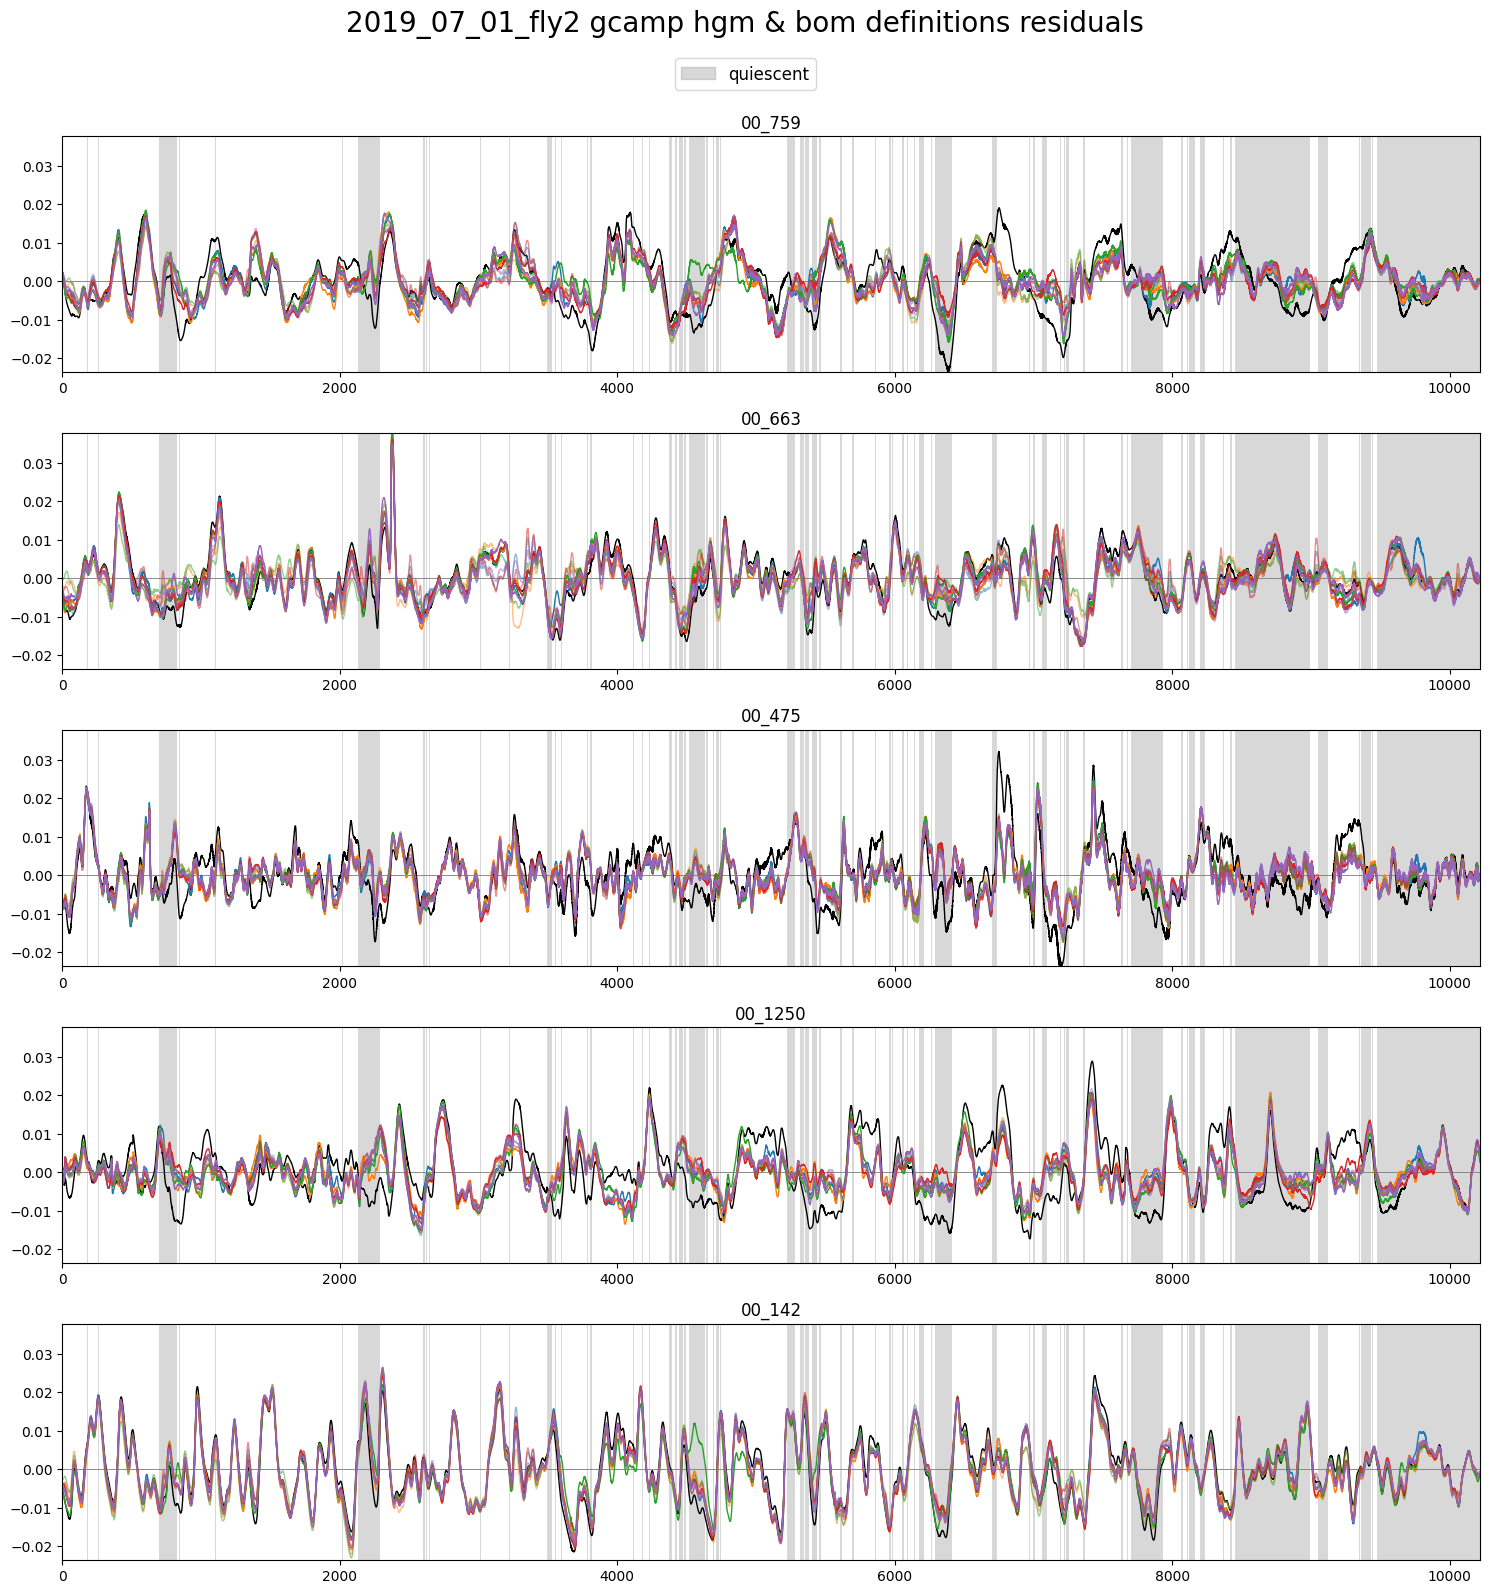

In [10]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neuron_labels] for i in range(splits)],
	[bom_res[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	states[['still']], label='quiescent',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

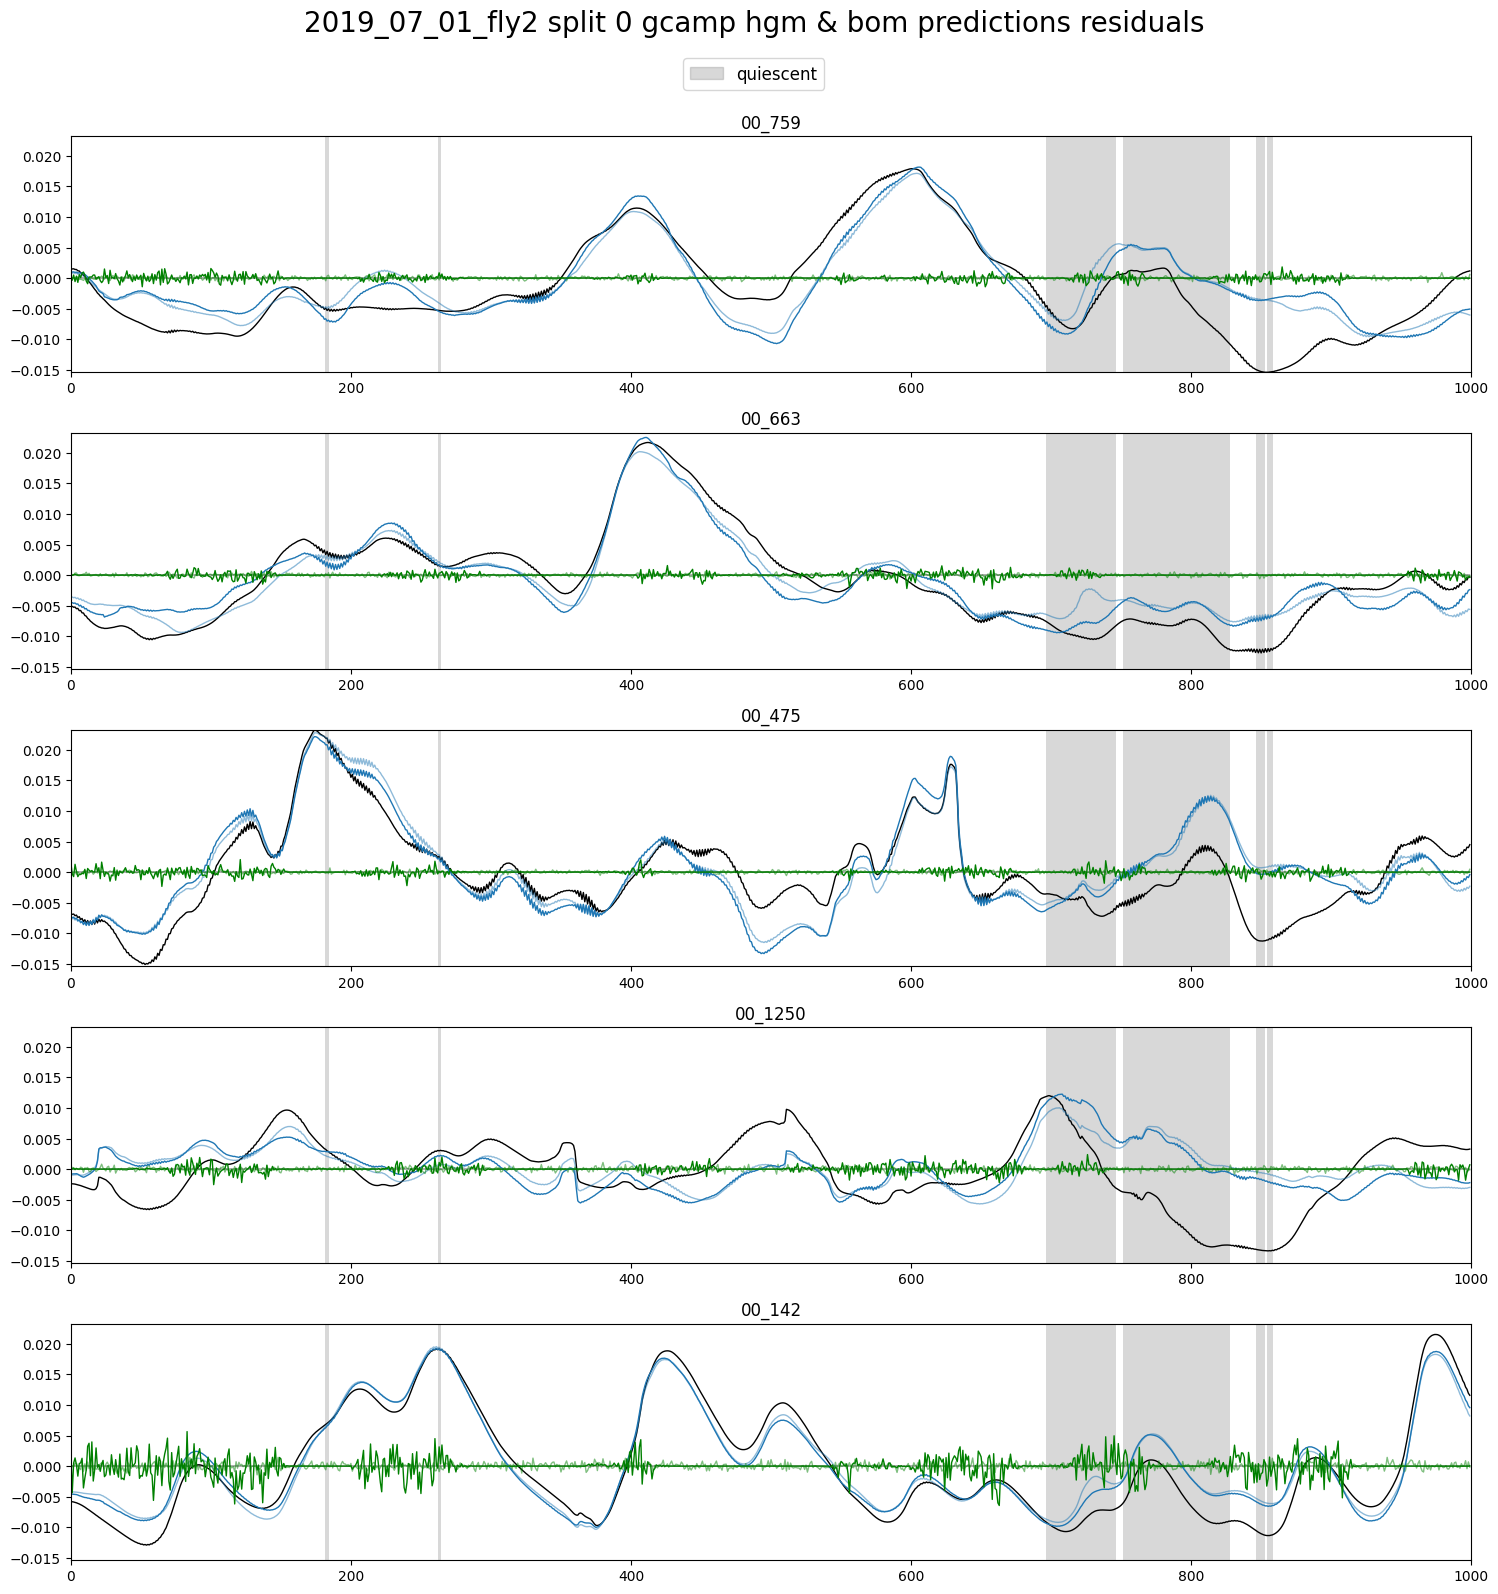

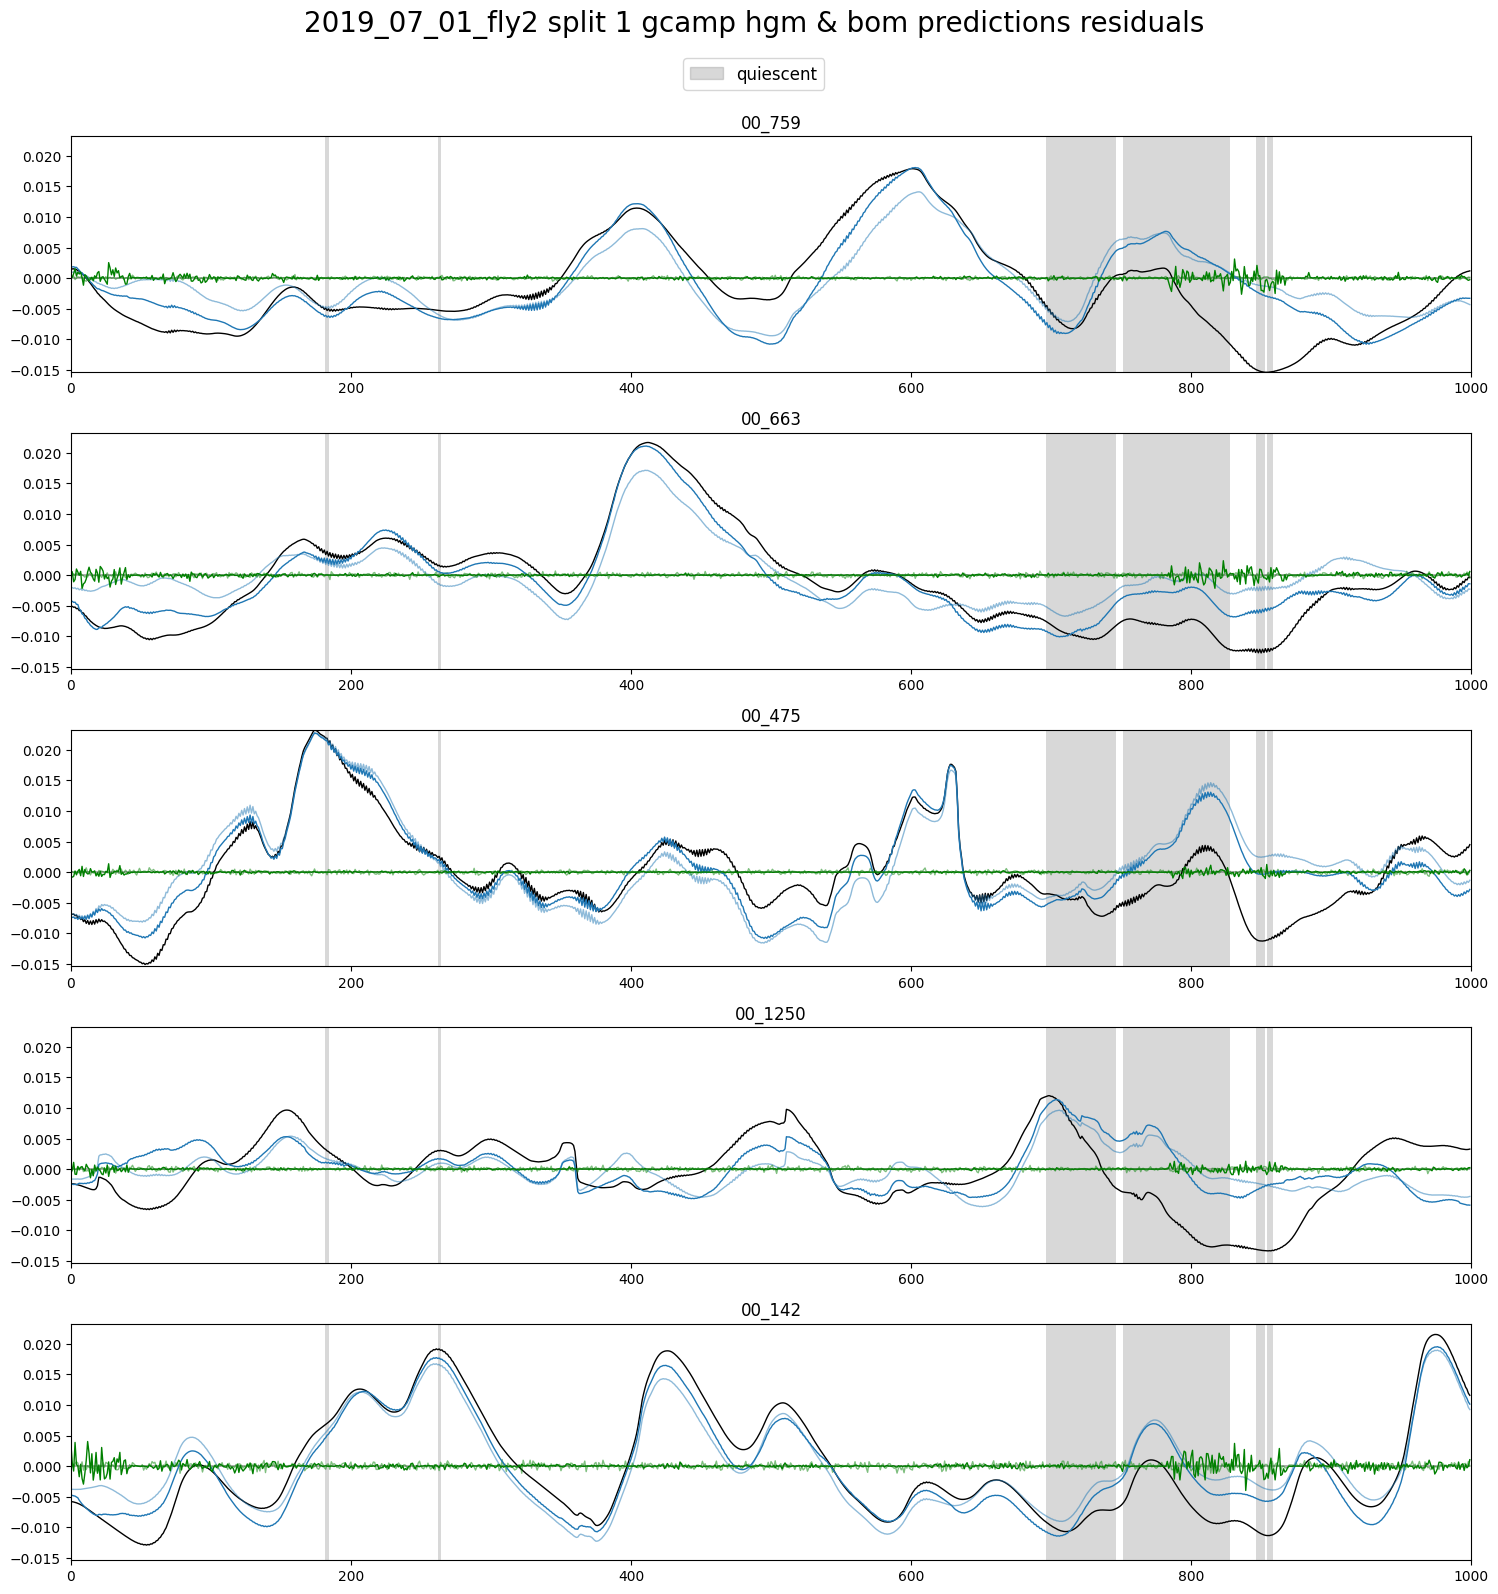

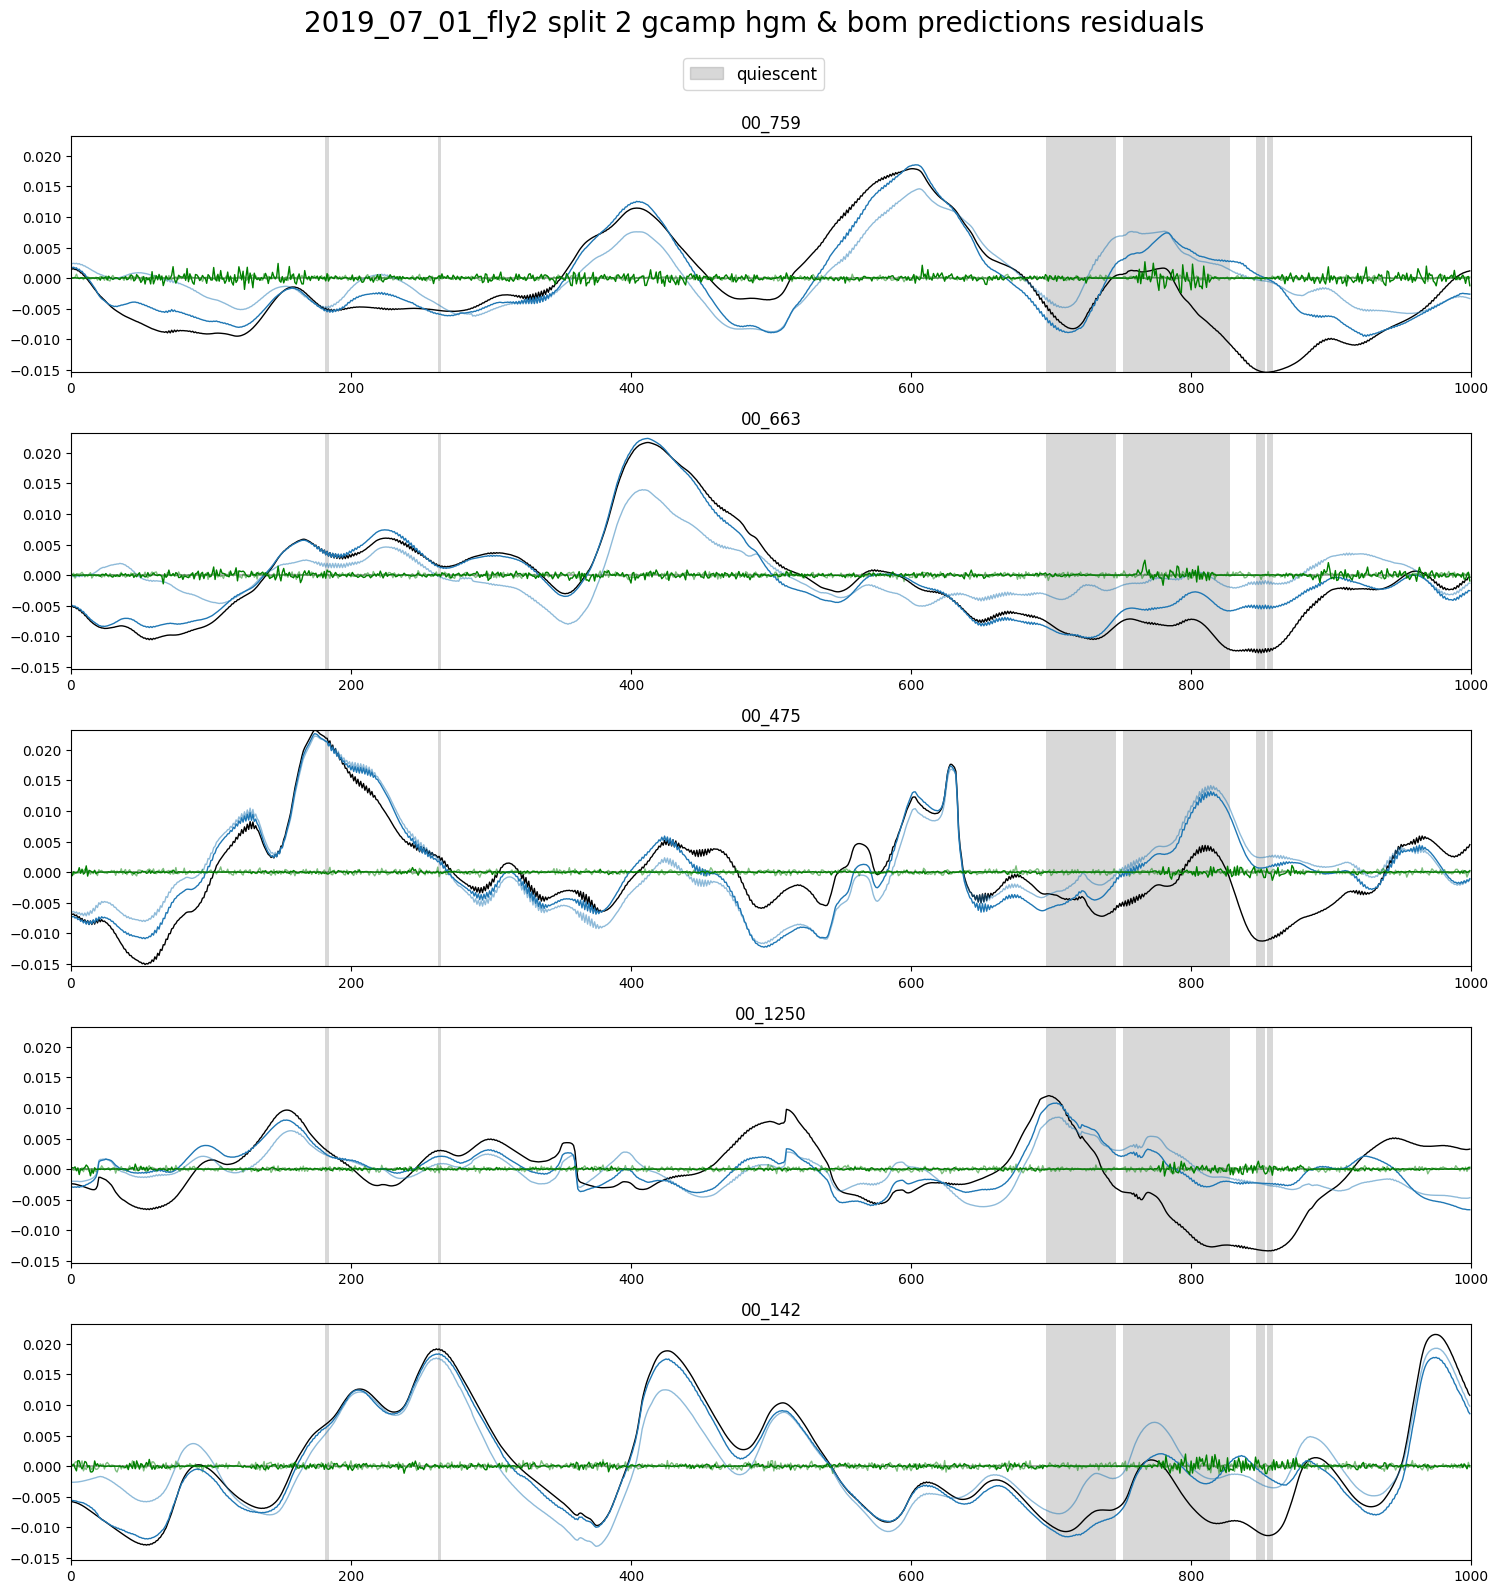

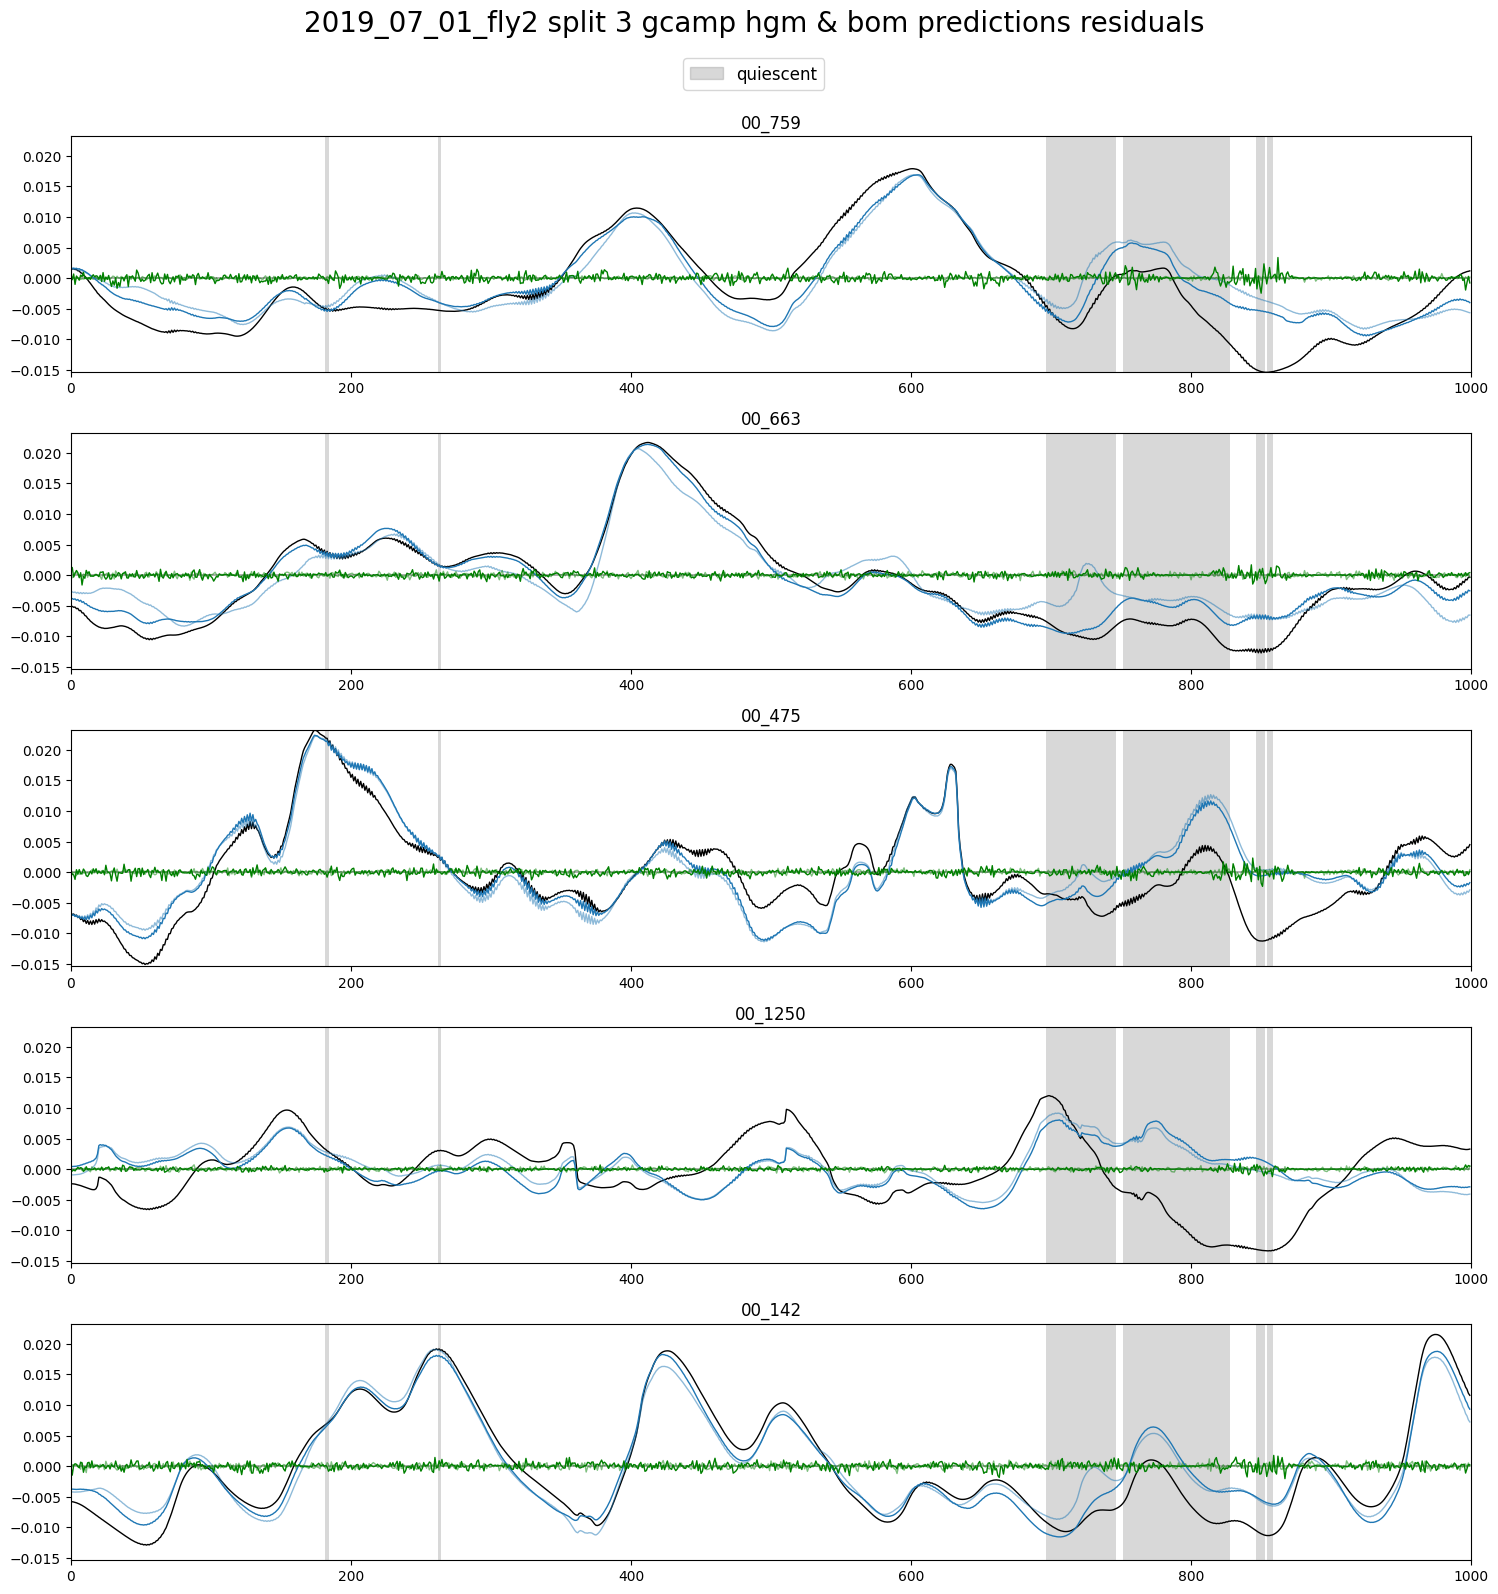

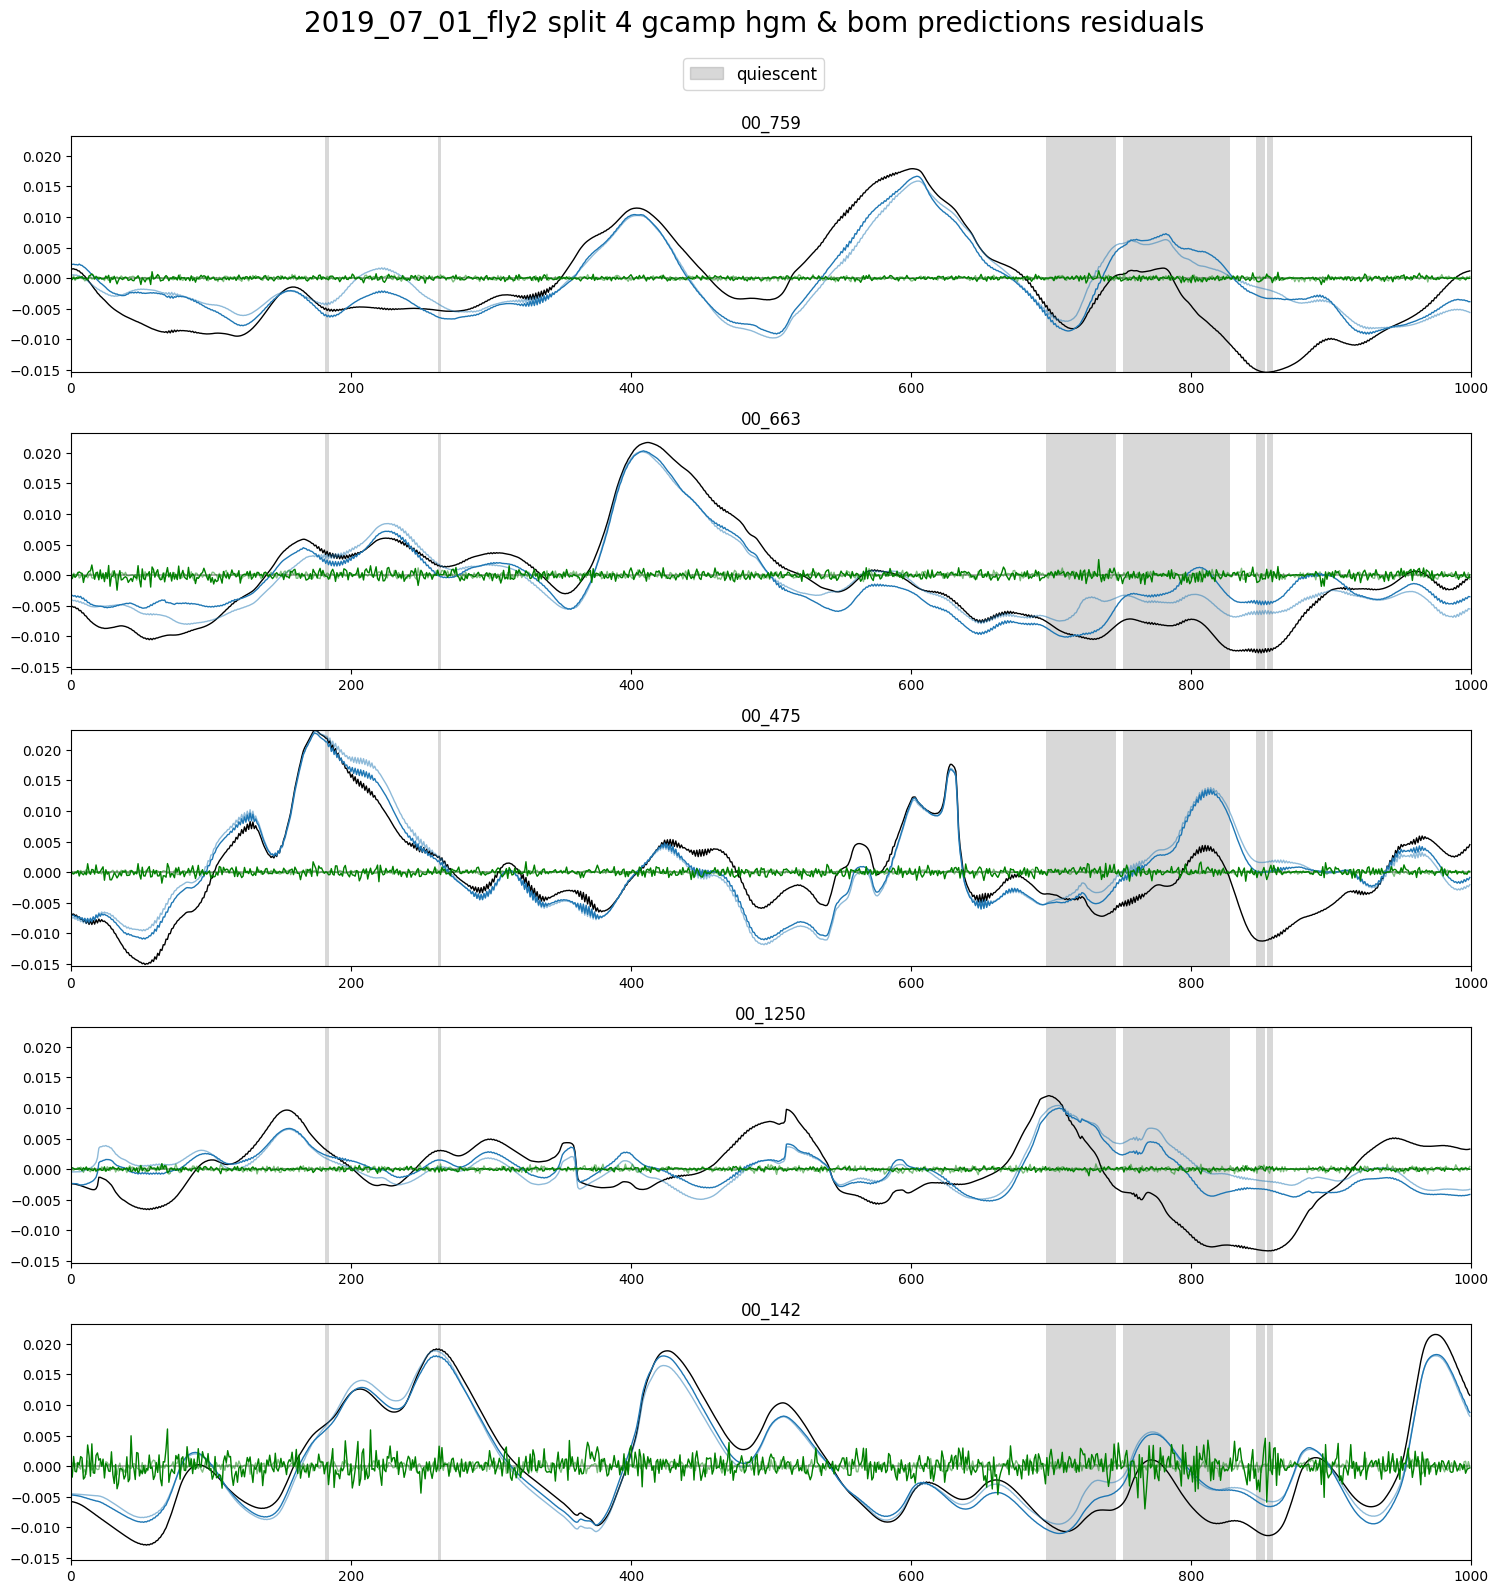

In [11]:
# max_x = traces.values.shape[0]
max_x = 1000

splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neuron_labels].iloc[:max_x, :],
		 hgm_pres[i][neuron_labels].iloc[:max_x, :]],
		[bom_res[i][neuron_labels].iloc[:max_x, :],
		 bom_pres[i][neuron_labels].iloc[:max_x, :]],
		traces[neuron_labels].iloc[:max_x, :],
		states[['still']].iloc[:max_x, :], label='quiescent',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

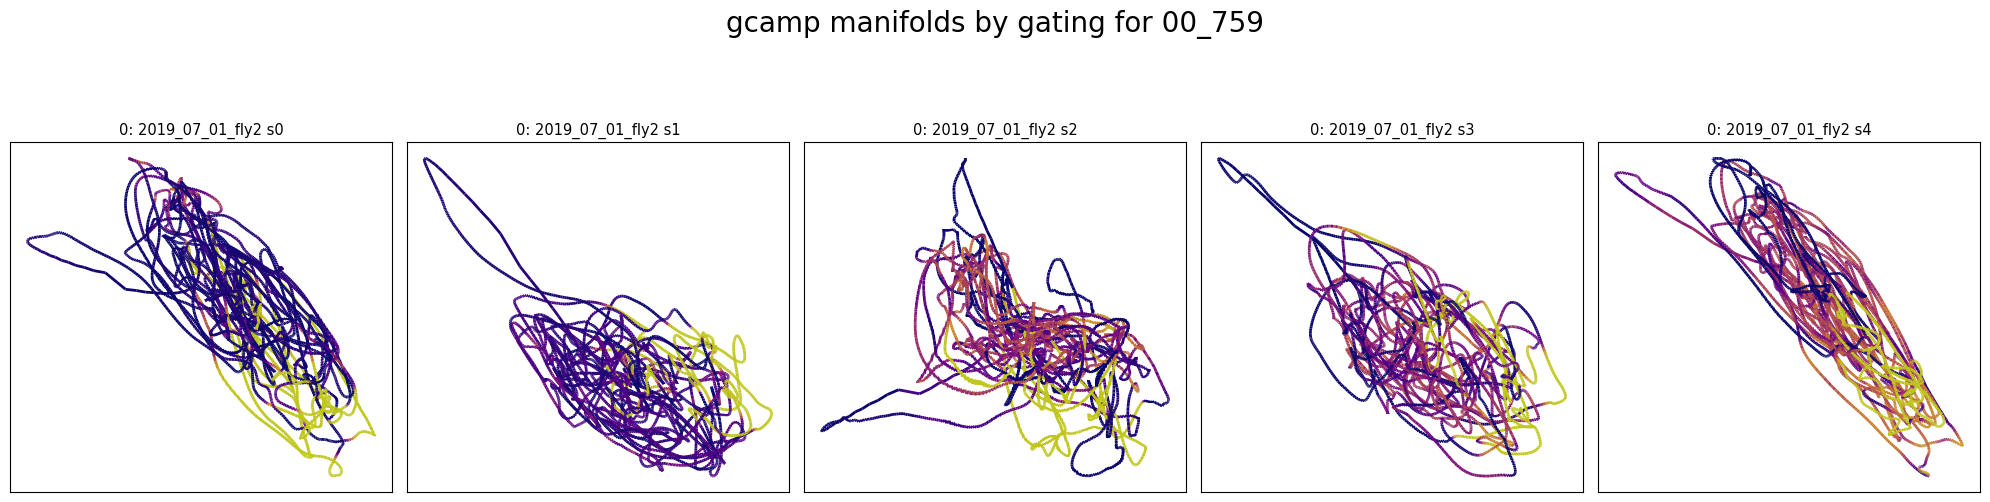

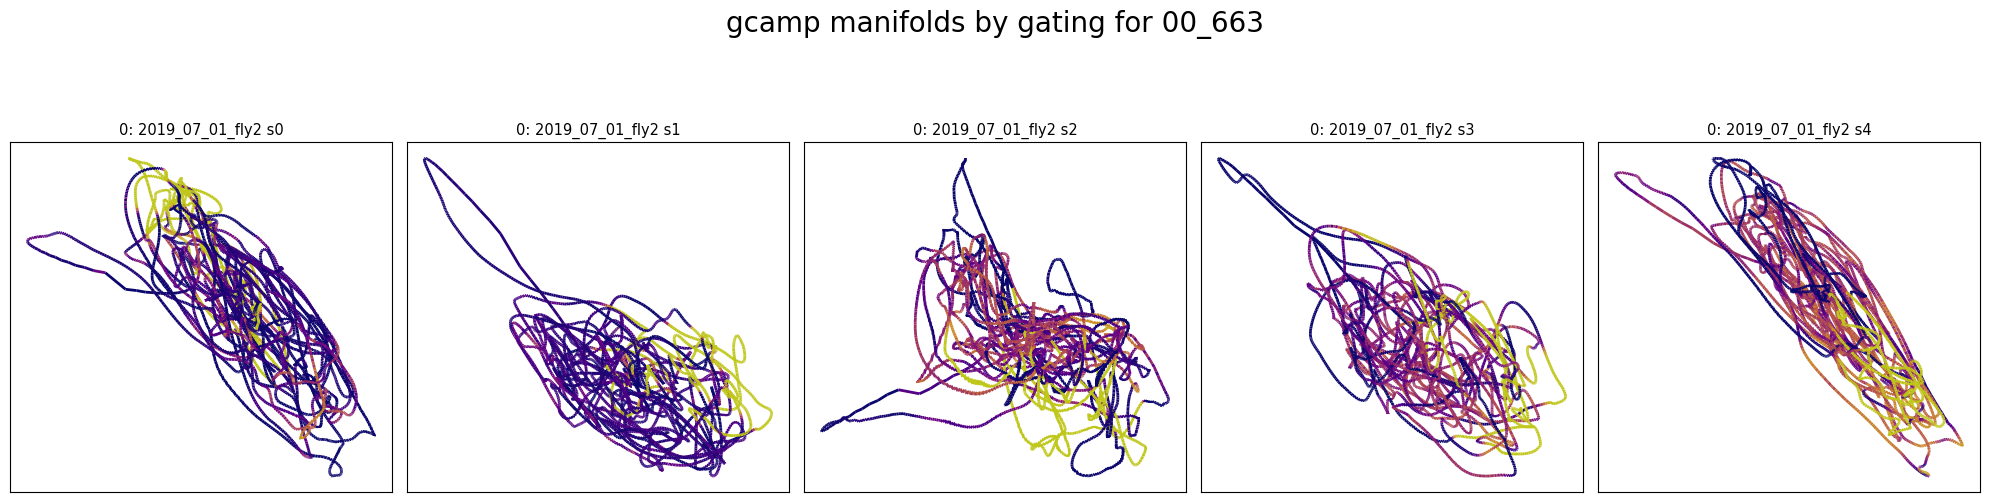

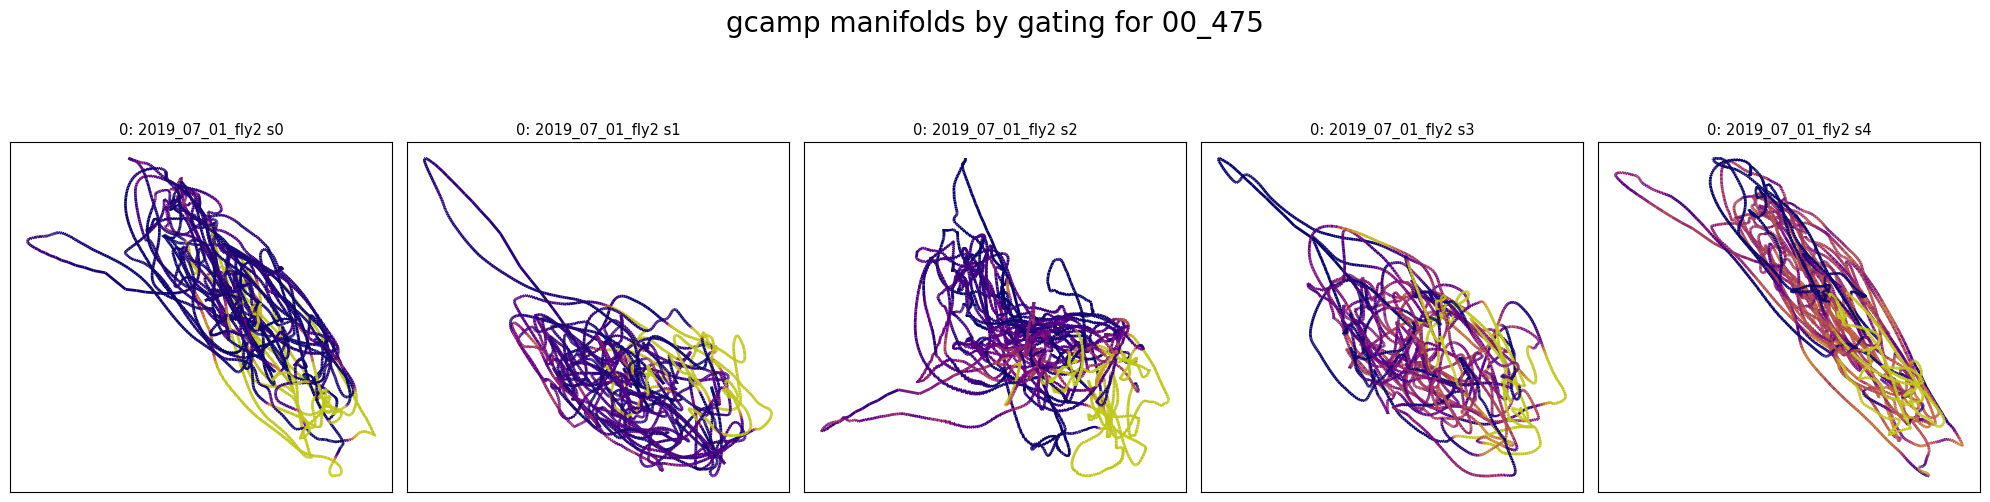

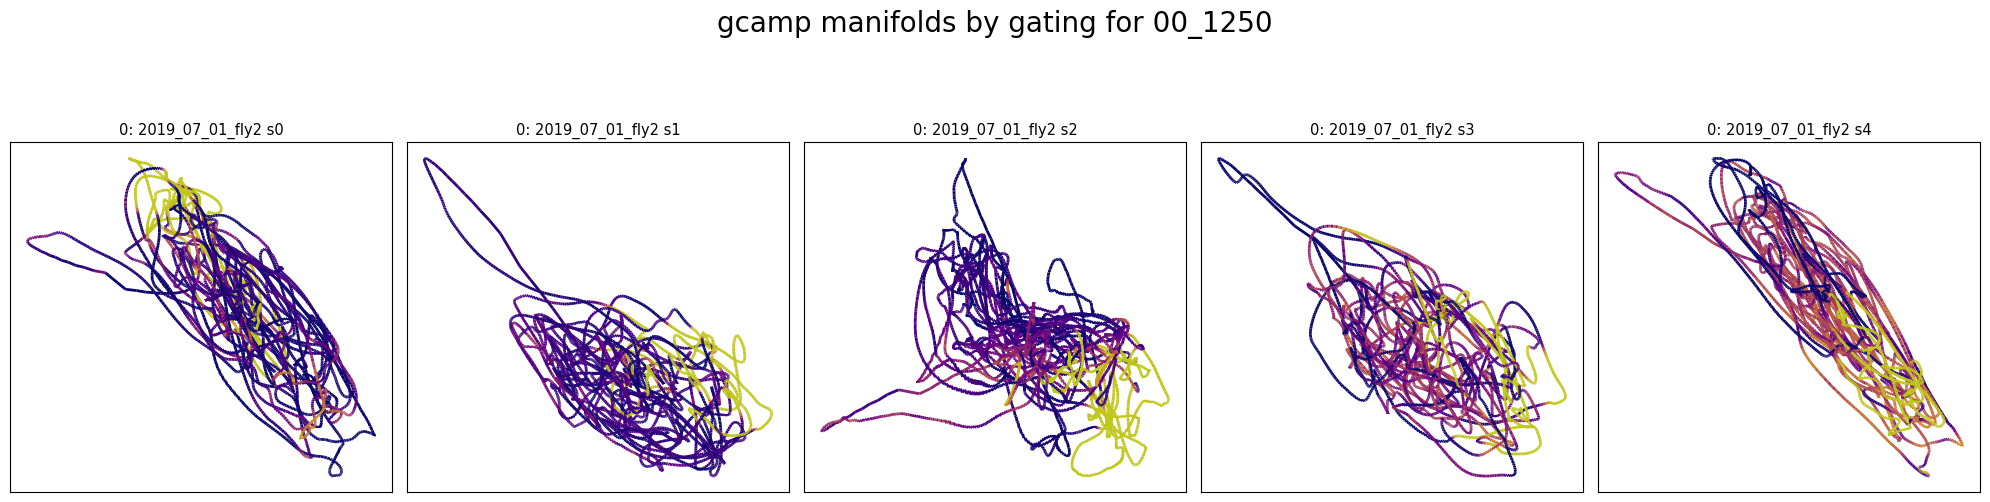

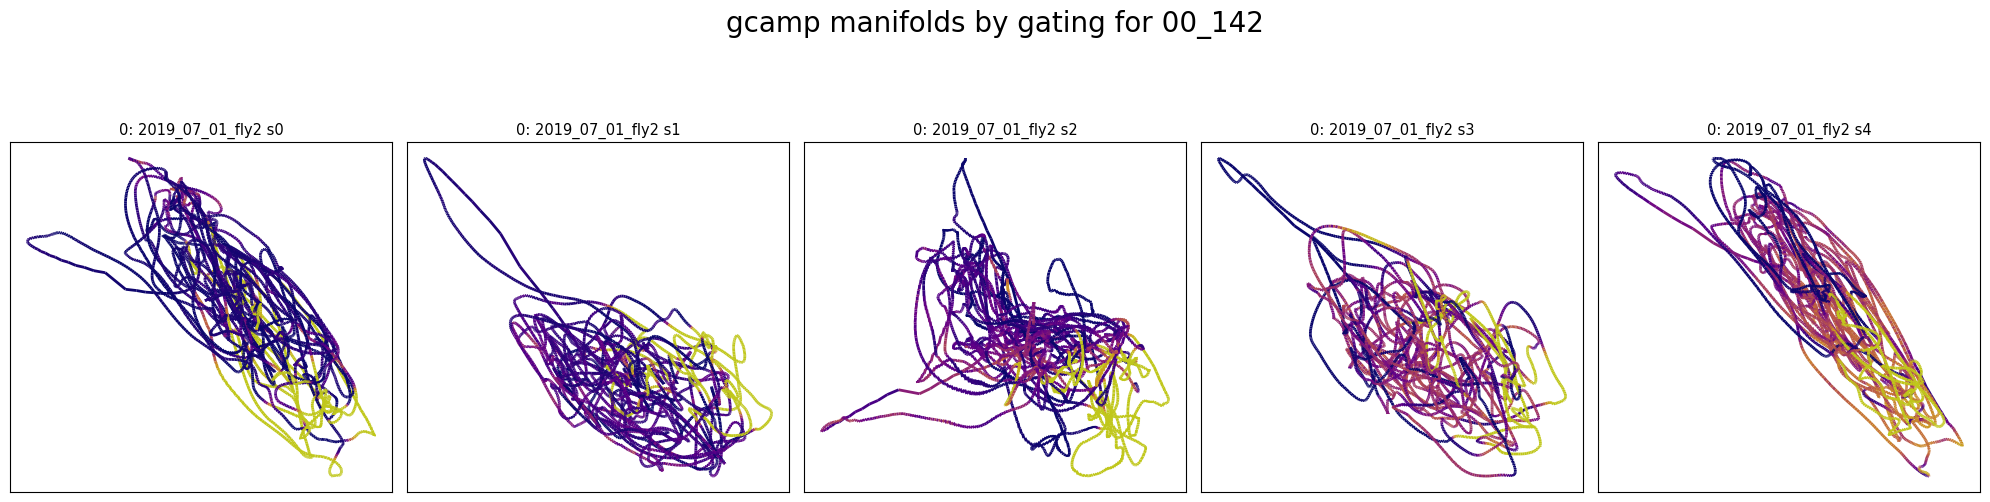

In [12]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

hgm_folder = f'{data_variant}_hgm_{model_variant}_' + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()])
hgm_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', hgm_folder), filename)

neurons = neuron_labels
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neurons]

splits = 5

for neuron_id in neuron_ids:
	sigmoid_terms = list()
	for split in range(splits):
		manifold_term = hgm_man[split].values
		manifold_term_zs = (manifold_term - manifold_term.mean(axis=0)) / np.where((N_std := manifold_term.std(axis=0)) == 0.0, 1.0, N_std)

		WM = hgm_params[split]['model']['WM'][:, neuron_id]

		sigmoid_term = sigmoid(manifold_term_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
							  [hgm_man[s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  None, None,
							  title=f'gcamp manifolds by gating for {traces.columns[neuron_id]}', plots_per_row=splits, top_space=1,
							  save_path=None)